# Program-defined perturbation-class occupancy analysis

This notebook defines cell states using the **global dominant cNMF program**, not Leiden clusters. It then asks whether biological targets redistribute cells among the curated program-defined states.

The workflow does **not** use target-to-program CRT effects or target-to-program differential-effect results.

Primary state rule:

1. Compute the global argmax across all 50 cell-level cNMF usages.
2. Do not force cells into the curated set.
3. Retain a cell in the primary analysis only when its global dominant program is in the curated primary table and the program's expected day matches the observed collection day.


In [1]:
from pathlib import Path
import os, sys, subprocess, json, zipfile
import pandas as pd
import yaml
from IPython.display import display, Image, SVG

NOTEBOOK_PATH = Path.cwd()
PACKAGE_DIR = NOTEBOOK_PATH.parent if NOTEBOOK_PATH.name == "notebooks" else NOTEBOOK_PATH
PACKAGE_DIR = PACKAGE_DIR.resolve()
CONFIG = PACKAGE_DIR / "config" / "program_defined_class_occupancy_config.yaml"

print("PACKAGE_DIR:", PACKAGE_DIR)
print("CONFIG:", CONFIG)
assert CONFIG.exists(), CONFIG


PACKAGE_DIR: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728
CONFIG: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/config/program_defined_class_occupancy_config.yaml


## 1. Inspect the curated program-state table

The primary list was transcribed from the first Hunter/Kyle annotation table. Programs flagged as uncertain or recommended for removal are retained only for sensitivity analysis, and programs marked for elimination are excluded.

In [2]:
cfg = yaml.safe_load(CONFIG.read_text())
program_table_path = PACKAGE_DIR / cfg["curated_program_states_tsv"]
program_table = pd.read_csv(program_table_path, sep="\t")

display(program_table)
print("Primary programs:", program_table.query("use_in_primary == True")["program_id"].tolist())
print("Expanded sensitivity programs:", program_table.query("use_in_expanded_sensitivity == True")["program_id"].tolist())


,program_number,program_id,expected_day,program_name,representative_genes,use_in_primary,use_in_expanded_sensitivity,curation_status,curation_note,plot_order
0,7,P7,D0,Pluripotency,L1TD1;DPPA4;TERF1;SOX2,True,True,curated,Included in first-table curated set,1
1,22,P22,D0,Pluripotency,POU5F1;TDGF1;DNMT3B,True,True,curated,Included in first-table curated set,2
2,29,P29,D0,Pluripotency,ESRG;DPPA4;NANOG,True,True,curated,Included in first-table curated set,3
3,28,P28,D1,Primitive streak,MIXL1;TBXT;SP5,True,True,curated,Included in first-table curated set,4
4,13,P13,D1,Posterior primitive streak,NKD1;CDX2;MSX1,True,True,curated,Included in first-table curated set,5
5,30,P30,D1,"Primitive streak, BMP-repressed 1",DKK1;NKD1;TBXT,True,True,curated,Included in first-table curated set,6
6,48,P48,D1,"Primitive streak, BMP-repressed 2",NKD1;TBXT;WLS,True,True,curated,Included in first-table curated set,7
7,15,P15,D2,Vascular progenitor,TAL1;FLI1;SOX7,True,True,reviewed named,Named in first table and retained for primary ...,8
8,14,P14,D2,Lateral mesoderm,HAND1;HAND2,True,True,reviewed named,Named in first table and retained for primary ...,9
9,17,P17,D2,"Lateral mesoderm, YAP/TAZ-induced",KRT8;KRT18;ANKRD1,True,True,reviewed named,Named in first table and retained for primary ...,10


Primary programs: ['P7', 'P22', 'P29', 'P28', 'P13', 'P30', 'P48', 'P15', 'P14', 'P17', 'P33', 'P34', 'P2', 'P3', 'P8', 'P11']
Expanded sensitivity programs: ['P7', 'P22', 'P29', 'P28', 'P13', 'P30', 'P48', 'P15', 'P14', 'P17', 'P33', 'P34', 'P2', 'P3', 'P8', 'P11', 'P23', 'P19', 'P27', 'P24']


## 2. Verify the real CC-Perturb-seq H5AD

The path below was recovered from the earlier analysis notebooks. The object should contain D0-D3 metadata, guide assignments, and cell-level cNMF usages.

In [3]:
query_path = Path(cfg["query_h5ad"])
print(query_path)
assert query_path.exists(), f"Query H5AD does not exist: {query_path}"
print("Size (GB):", round(query_path.stat().st_size / 1e9, 2))

usage_path = Path(cfg.get("program_usage_file", "")) if cfg.get("program_usage_file") else None
print("External cNMF usage table:", usage_path)
if usage_path is not None:
    assert usage_path.exists(), f"External cNMF usage file does not exist: {usage_path}"

# Preflight: the base H5AD may not persist cnmf_usage/Program columns because
# those were added in memory in ipsc-ec.Hippo.figure.ipynb.
import anndata as ad
_ad = ad.read_h5ad(query_path, backed="r")
program_obs_cols = [c for c in _ad.obs.columns if str(c).startswith("Program ")]
print("Program columns stored in H5AD:", len(program_obs_cols))
print("cnmf_usage stored in H5AD obsm:", "cnmf_usage" in _ad.obsm)
print("Exporter will use external table when neither is persisted.")
_ad.file.close()


/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
Size (GB): 4.22
External cNMF usage table: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.usages.k_50.dt_0_2.consensus.txt
Program columns stored in H5AD: 0
cnmf_usage stored in H5AD obsm: False
Exporter will use external table when neither is persisted.


## 3. Export program-defined cell states and target-union assignments

This step reads the H5AD once, computes the global dominant program across all 50 programs, maps targeting guides to `intended_target_name`, and writes compact analysis tables.

In [4]:
export_script = PACKAGE_DIR / "scripts" / "00_export_program_defined_occupancy_inputs.py"
cmd = [sys.executable, str(export_script), "--config", str(CONFIG)]
print(" ".join(cmd))
proc = subprocess.run(
    cmd, cwd=PACKAGE_DIR, text=True,
    stdout=subprocess.PIPE, stderr=subprocess.STDOUT
)
print(proc.stdout)
if proc.returncode != 0:
    raise RuntimeError(
        f"Exporter failed with return code {proc.returncode}. "
        "The complete child-process traceback is printed immediately above."
    )


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/scripts/00_export_program_defined_occupancy_inputs.py --config /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/config/program_defined_class_occupancy_config.yaml
Reading H5AD in backed mode: /oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pipeline/3.integrated_days/3.all_days_concat_pc30_all_genes_sceptre_guides.h5ad
Reading external cNMF usage table: /oak/stanford/groups/engreitz/Users/ymo/IGVF_ccperturbseq/Result/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50/030526_100k_cells_100iter_allHVG_torch_halsvar_batch_e7_50.usages.k_50.dt_0_2.consensus.txt
cNMF usage overlap: 121,616/121,616 cells (100.0%)
{
  "query_h5ad": "/oak/stanford/groups/engreitz/Users/opushkar/cc_perturb/2.preprocessing_tonys_pi

## 4. Audit program-state coverage

Important checks:

- fraction of each observed day represented by the primary curated program states;
- replicate representation;
- non-curated dominant programs that are excluded from the primary model;
- carrier coverage by day.


In [5]:
cfg = yaml.safe_load(CONFIG.read_text())
export_dir = Path(cfg["export_dir"])
if not export_dir.is_absolute():
    export_dir = PACKAGE_DIR / export_dir

for fn in [
    "program_state_assignment_qc.tsv",
    "program_state_counts_by_day_and_replicate.tsv",
    "dominant_program_counts_by_day.tsv",
    "control_definition_qc.tsv",
    "target_carrier_counts_by_day.tsv",
]:
    path = export_dir / fn
    print("\n###", fn)
    display(pd.read_csv(path, sep="\t").head(50))



### program_state_assignment_qc.tsv


,day,n_all_cells,n_has_program_usage,n_primary_curated_dominant,n_primary_program_state,n_expanded_program_state,n_pure_controls,n_mixed_control_target,fraction_with_program_usage,fraction_in_primary_program_state
0,D0,38609,38609,16360,16350,16350,202,6573,1.0,0.423476
1,D1,16925,16925,10022,9977,9977,75,3209,1.0,0.589483
2,D2,21980,21980,11614,11594,18010,93,4213,1.0,0.527480
3,D3,44102,44102,31953,31532,38002,378,6928,1.0,0.714979



### program_state_counts_by_day_and_replicate.tsv


,day,biological_replicate,assigned_state,assigned_program_name,n_cells,median_dominant_fraction
0,D0,d0_rep1,P22,Pluripotency,208,0.157566
1,D0,d0_rep1,P29,Pluripotency,213,0.169667
2,D0,d0_rep1,P7,Pluripotency,8746,0.211443
3,D0,d0_rep2,P22,Pluripotency,3743,0.181114
4,D0,d0_rep2,P29,Pluripotency,1049,0.158684
5,D0,d0_rep2,P7,Pluripotency,2391,0.213371
6,D1,d1_rep1,P13,Posterior primitive streak,1650,0.204289
7,D1,d1_rep1,P28,Primitive streak,2376,0.194283
8,D1,d1_rep1,P30,"Primitive streak, BMP-repressed 1",667,0.201416
9,D1,d1_rep1,P48,"Primitive streak, BMP-repressed 2",69,0.199200



### dominant_program_counts_by_day.tsv


,day,global_dominant_program_id,global_dominant_program_name,n_cells,median_dominant_fraction
0,D0,P0,Non-curated program,316,0.154922
1,D0,P1,Non-curated program,53,0.183861
2,D0,P10,Non-curated program,158,0.133995
3,D0,P12,Non-curated program,34,0.136656
4,D0,P16,Non-curated program,1,0.366218
5,D0,P18,Non-curated program,7,0.114846
6,D0,P20,Non-curated program,2,0.147813
7,D0,P21,Eliminated,1719,0.174639
8,D0,P22,Pluripotency,3951,0.180207
9,D0,P25,Non-curated program,2873,0.276729



### control_definition_qc.tsv


,day,biological_replicate,n_cells,n_pure_controls,n_mixed_control_target,n_any_targeting
0,D0,d0_rep1,17488,75,3026,16263
1,D0,d0_rep2,21121,127,3547,19322
2,D1,d1_rep1,5856,27,1178,5505
3,D1,d1_rep2,11069,48,2031,10382
4,D2,d2_rep1,10895,41,2284,10295
5,D2,d2_rep2,11085,52,1929,10182
6,D3,d3_rep1,21377,185,3282,19018
7,D3,d3_rep2,22725,193,3646,19641



### target_carrier_counts_by_day.tsv


,target_name,day,n_carrier_cells,n_carrier_cells_in_primary_program_states,median_guides_for_target
0,ACAA1,D0,591,271,1.0
1,ACAA1,D1,336,173,1.0
2,ACAA1,D2,405,204,1.0
3,ACAA1,D3,634,411,1.0
4,ACTL7B,D0,597,252,1.0
5,ACTL7B,D1,302,163,1.0
6,ACTL7B,D2,407,190,1.0
7,ACTL7B,D3,638,381,1.0
8,ACVR1B,D0,650,283,1.0
9,ACVR1B,D1,293,175,1.0


## 5. Fit target-level occupancy models and create the class summary

For each observed day, target, and curated dominant-program state, the script fits a one-versus-rest logistic model with the established technical covariates. Target classes are summarized only after the target-level models are fitted.

In [6]:
analysis_script = PACKAGE_DIR / "scripts" / "01_fit_program_defined_occupancy_and_plot.py"
cmd = [sys.executable, str(analysis_script), "--config", str(CONFIG)]
print(" ".join(cmd))
subprocess.run(cmd, check=True, cwd=PACKAGE_DIR)


/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/scripts/01_fit_program_defined_occupancy_and_plot.py --config /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/config/program_defined_class_occupancy_config.yaml


[Parallel(n_jobs=8)]: Using backend LokyBackend with 8 concurrent workers.
[Parallel(n_jobs=8)]: Done   2 tasks      | elapsed:    3.1s
[Parallel(n_jobs=8)]: Done   9 tasks      | elapsed:    3.7s
[Parallel(n_jobs=8)]: Done  16 tasks      | elapsed:    5.0s
[Parallel(n_jobs=8)]: Done  25 tasks      | elapsed:    6.7s
[Parallel(n_jobs=8)]: Done  34 tasks      | elapsed:    8.7s
[Parallel(n_jobs=8)]: Done  45 tasks      | elapsed:   10.8s
[Parallel(n_jobs=8)]: Done  56 tasks      | elapsed:   13.0s
[Parallel(n_jobs=8)]: Done  69 tasks      | elapsed:   15.9s
[Parallel(n_jobs=8)]: Done  82 tasks      | elapsed:   18.3s
[Parallel(n_jobs=8)]: Done  97 tasks      | elapsed:   21.4s
[Parallel(n_jobs=8)]: Done 112 tasks      | elapsed:   24.3s
[Parallel(n_jobs=8)]: Done 129 tasks      | elapsed:   27.8s
[Parallel(n_jobs=8)]: Done 146 tasks      | elapsed:   31.1s
[Parallel(n_jobs=8)]: Done 165 tasks      | elapsed:   35.1s
[Parallel(n_jobs=8)]: Done 184 tasks      | elapsed:   38.8s
[Parallel(

{
  "n_all_cells": 121616,
  "n_primary_program_state_cells": 69453,
  "n_targets_with_assignments": 298,
  "n_target_program_state_tests": 4752,
  "n_classes_displayed": 10,
  "state_definition": "global dominant cNMF program; primary curated program list; expected-day match",
  "target_to_program_differential_effects_used": false
}


CompletedProcess(args=['/oak/stanford/groups/engreitz/Users/tri/envs/sc-dl/bin/python', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/scripts/01_fit_program_defined_occupancy_and_plot.py', '--config', '/oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/config/program_defined_class_occupancy_config.yaml'], returncode=0)

## 6. Inspect the main results and coverage

In [7]:
cfg = yaml.safe_load(CONFIG.read_text())
result_dir = Path(cfg["output_dir"])
if not result_dir.is_absolute():
    result_dir = PACKAGE_DIR / result_dir

for fn in [
    "class_program_state_occupancy_summary.tsv",
    "class_coverage_summary.tsv",
    "coverage_and_filtering.tsv",
    "target_class_program_state_raw_distribution.tsv",
    "analysis_audit.json",
]:
    path = result_dir / fn
    print("\n###", fn)
    if path.suffix == ".json":
        print(path.read_text())
    else:
        display(pd.read_csv(path, sep="\t").head(80))



### class_program_state_occupancy_summary.tsv


,analysis_population,regulator_class,day,state,n_evaluable_targets,median_log_odds_ratio,fraction_significant_in_displayed_direction,n_significant_in_displayed_direction,displayed_direction
0,primary_curated_dominant_expected_day,Apoptosis / cell cycle / stress,D0,P22,19,-0.086249,0.000000,0,depleted
1,primary_curated_dominant_expected_day,Apoptosis / cell cycle / stress,D0,P29,19,0.028386,0.000000,0,enriched
2,primary_curated_dominant_expected_day,Apoptosis / cell cycle / stress,D0,P7,19,0.067475,0.000000,0,enriched
3,primary_curated_dominant_expected_day,Apoptosis / cell cycle / stress,D1,P13,19,0.094020,0.000000,0,enriched
4,primary_curated_dominant_expected_day,Apoptosis / cell cycle / stress,D1,P28,19,-0.099223,0.000000,0,depleted
...,...,...,...,...,...,...,...,...,...
75,primary_curated_dominant_expected_day,Other reviewed regulators,D3,P2,18,-0.094316,0.000000,0,depleted
76,primary_curated_dominant_expected_day,Other reviewed regulators,D3,P3,18,-0.057749,0.166667,3,depleted
77,primary_curated_dominant_expected_day,Other reviewed regulators,D3,P33,18,-0.081740,0.000000,0,depleted
78,primary_curated_dominant_expected_day,Other reviewed regulators,D3,P34,18,0.009345,0.111111,2,enriched



### class_coverage_summary.tsv


,regulator_class,minimum_evaluable_targets,maximum_evaluable_targets,n_day_program_combinations
0,Apoptosis / cell cycle / stress,18,19,16
1,Chromatin regulation,28,31,16
2,Hippo / YAP,5,6,16
3,Metabolism / trafficking / adhesion,35,41,16
4,Other reviewed regulators,17,18,16
5,TGF/BMP/Activin,7,9,16
6,Transcription / RNA processing,61,68,16
7,Translation / proteostasis,36,41,16
8,VEGF / EC specification,4,4,15
9,WNT / mesoderm regulators,5,6,16



### coverage_and_filtering.tsv


,analysis_population,day,target_name,n_analysis_cells,n_carrier_cells,passes_carrier_threshold,n_evaluable_program_states
0,primary_curated_dominant_expected_day,D0,ACAA1,16350,271,True,3
1,primary_curated_dominant_expected_day,D0,ACTL7B,16350,252,True,3
2,primary_curated_dominant_expected_day,D0,ACVR1B,16350,283,True,3
3,primary_curated_dominant_expected_day,D0,ACVR2A,16350,309,True,3
4,primary_curated_dominant_expected_day,D0,ACVR2B,16350,349,True,3
...,...,...,...,...,...,...,...
75,primary_curated_dominant_expected_day,D0,ERCC2,16350,260,True,3
76,primary_curated_dominant_expected_day,D0,ERO1A,16350,374,True,3
77,primary_curated_dominant_expected_day,D0,ETS1,16350,389,True,3
78,primary_curated_dominant_expected_day,D0,ETV2,16350,365,True,3



### target_class_program_state_raw_distribution.tsv


,regulator_class,day,assigned_state,n_unique_carrier_cells,n_targets_observed,n_state_cells,raw_fraction_of_state_cells_with_class_target
0,Apoptosis / cell cycle / stress,D0,P22,1011,19,3951,0.255885
1,Apoptosis / cell cycle / stress,D0,P29,308,19,1262,0.244057
2,Apoptosis / cell cycle / stress,D0,P7,2946,19,11137,0.264524
3,Apoptosis / cell cycle / stress,D1,P13,1158,19,4298,0.269428
4,Apoptosis / cell cycle / stress,D1,P28,1104,19,3615,0.305394
...,...,...,...,...,...,...,...
75,Other reviewed regulators,D3,P2,1361,18,8499,0.160136
76,Other reviewed regulators,D3,P3,2058,18,11993,0.171600
77,Other reviewed regulators,D3,P33,786,18,2688,0.292411
78,Other reviewed regulators,D3,P34,416,18,1186,0.350759



### analysis_audit.json
{
  "n_all_cells": 121616,
  "n_primary_program_state_cells": 69453,
  "n_targets_with_assignments": 298,
  "n_target_program_state_tests": 4752,
  "n_classes_displayed": 10,
  "state_definition": "global dominant cNMF program; primary curated program list; expected-day match",
  "target_to_program_differential_effects_used": false
}


## 7. Display the publication panel and supplementary heatmap

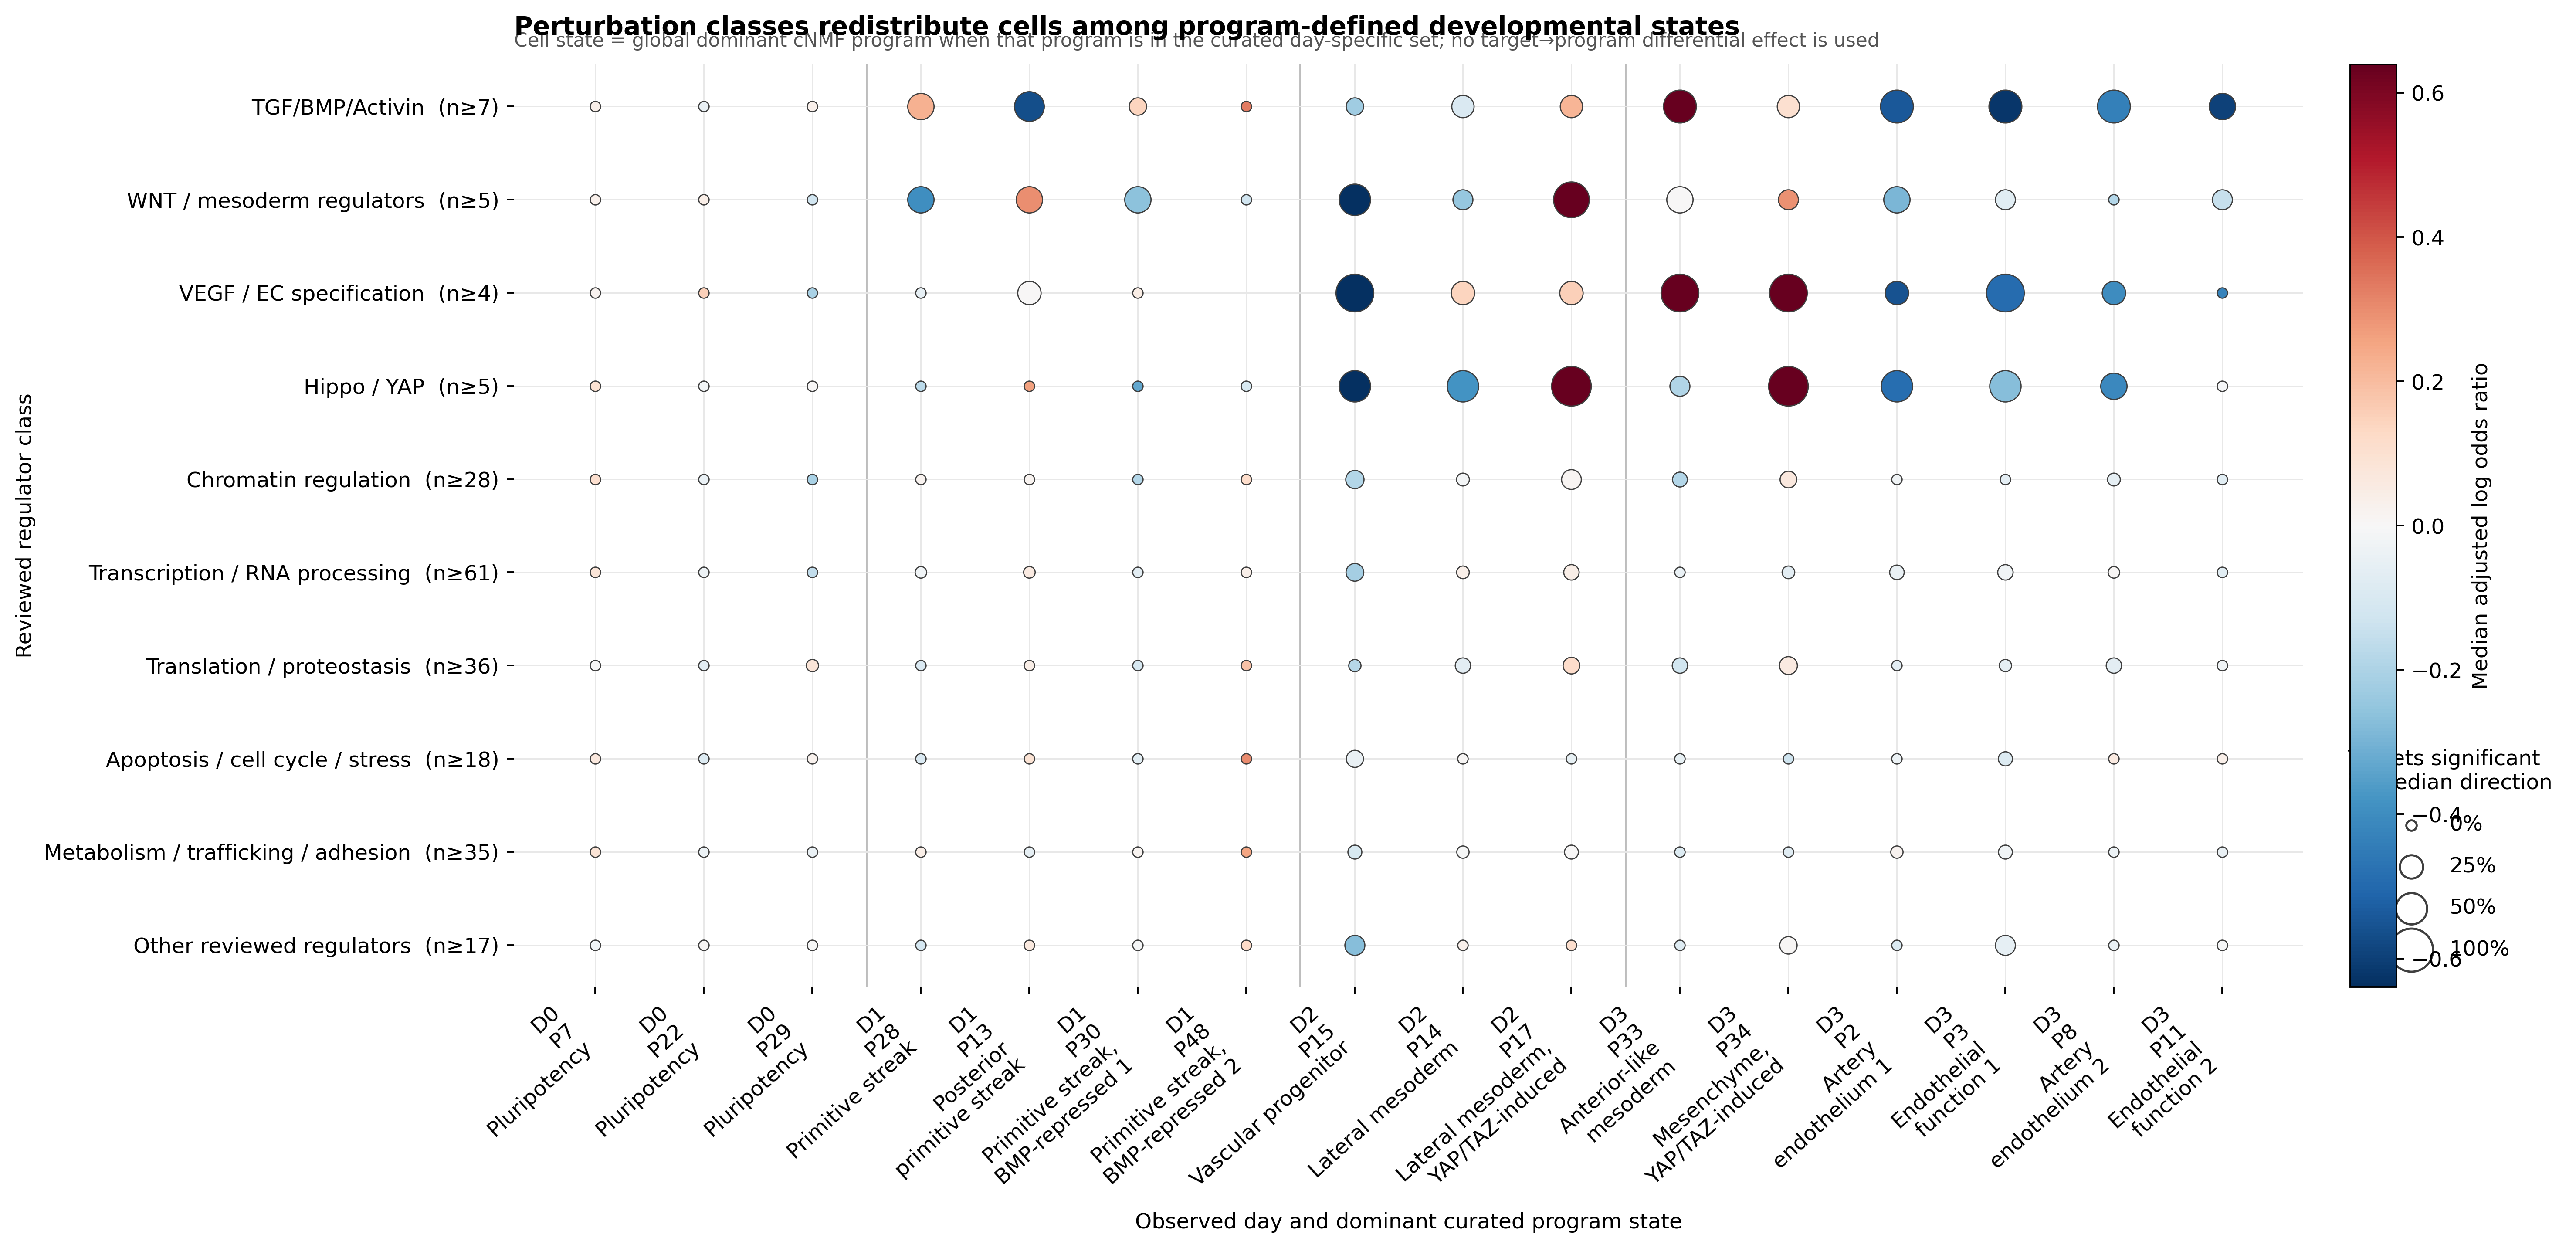

In [8]:
main_png = result_dir / "Fig2_perturbation_class_program_state_occupancy.png"
supp_png = result_dir / "Fig2_target_program_state_occupancy_heatmap_supplementary.png"

display(Image(filename=str(main_png)))
display(Image(filename=str(supp_png)))


## 8. Package the completed outputs

In [9]:
zip_path = PACKAGE_DIR / "program_defined_occupancy_results.zip"
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as zf:
    for p in result_dir.rglob("*"):
        if p.is_file():
            zf.write(p, arcname=str(p.relative_to(result_dir.parent)))
    for p in export_dir.glob("*.tsv"):
        zf.write(p, arcname=str(p.relative_to(export_dir.parent)))
    for p in export_dir.glob("*.json"):
        zf.write(p, arcname=str(p.relative_to(export_dir.parent)))
print("Wrote:", zip_path)


Wrote: /oak/stanford/groups/engreitz/Users/tri/CodeBase/programDE/notebooks/figure2_program_defined_class_occupancy_20260728/program_defined_occupancy_results.zip
